### Data Science Salaries 2023 - 추가 분석
### 학습 내용
 * 기본 EDA([01_19_DataScienceSalaries_Analysis_2305](https://ldjwj.github.io/dataAnalysis/01_19_DataScienceSalaries_Analysis_2305.html))에서 한 걸음 더 들어가기
 * **평균의 함정**(표본 수, 혼재 변수)을 피하는 비교 방법 익히기

### 내용
 * 0. 기본 EDA 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (코드값을 이해하기 쉬운 이름으로)
 * 2. 연봉을 결정하는 요인 - 경력 × 기업 규모 × 원격 근무
 * 3. 직무 그룹화와 신뢰할 수 있는 순위 - 직무 / 국가
 * 4. 정리

### 0. 기본 EDA 돌아보기 - 무엇을 보완할까?
 * **표본 수를 고려하지 않은 평균 비교**
   * 직무별 평균 연봉 1위 `Data Science Tech Lead`, 국가별 1위 `IL`(이스라엘)은 각각 **1명, 2명**의 데이터
   * 몇 명의 값으로 1위가 결정되면 일반화하기 어렵다.
 * **경력 코드의 의미**
   * `EN` Entry-level(신입/주니어), `MI` Mid-level(중급), `SE` **Senior**(시니어), `EX` **Executive**(임원/디렉터)
   * `SE`는 Software Engineer가 아니라 Senior를 의미한다.
 * **아직 살펴보지 않은 변수**
   * `remote_ratio`(원격 근무 비율), `company_size`(기업 규모), `employment_type`(고용 형태)
 * 이번 추가 분석에서는 **평균 대신 중앙값**을 주로 사용하고, **표본 수(count)를 항상 함께** 확인한다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비

In [2]:
file_path = "./data/dataScienceSalaries2023/ds_salaries.csv"
df = pd.read_csv(file_path)
df.shape

(3755, 11)

In [3]:
# 중복 행 확인
df.duplicated().sum()

np.int64(1171)

* 한줄 확인 : 모든 값이 같은 행이 1,171개 있다.
   * 이 데이터는 설문으로 수집되어 **같은 조건, 같은 연봉의 서로 다른 사람**일 수 있으므로 기본 EDA와 동일하게 **그대로 사용**한다.

#### 코드값을 이해하기 쉬운 이름으로 바꾸기
 * 순서가 있는 값(경력, 기업 규모)은 `Categorical`로 지정하면 그래프에서도 순서대로 표시된다.

In [4]:
exp_map = {'EN': '신입(EN)', 'MI': '중급(MI)', 'SE': '시니어(SE)', 'EX': '임원(EX)'}
size_map = {'S': '소기업(S)', 'M': '중기업(M)', 'L': '대기업(L)'}
remote_map = {0: '사무실(0%)', 50: '하이브리드(50%)', 100: '완전 원격(100%)'}
emp_map = {'FT': '정규직', 'PT': '파트타임', 'CT': '계약직', 'FL': '프리랜서'}

df['경력'] = pd.Categorical(df['experience_level'].map(exp_map), categories=exp_map.values(), ordered=True)
df['기업규모'] = pd.Categorical(df['company_size'].map(size_map), categories=size_map.values(), ordered=True)
df['근무형태'] = pd.Categorical(df['remote_ratio'].map(remote_map), categories=remote_map.values(), ordered=True)
df['고용형태'] = df['employment_type'].map(emp_map)
df['회사위치'] = np.where(df['company_location'] == 'US', '미국', '미국 외')
df['연봉(천달러)'] = df['salary_in_usd'] / 1000

df[['경력', '기업규모', '근무형태', '고용형태', '회사위치', '연봉(천달러)']].head()

,경력,기업규모,근무형태,고용형태,회사위치,연봉(천달러)
0,시니어(SE),대기업(L),완전 원격(100%),정규직,미국 외,85.847
1,중급(MI),소기업(S),완전 원격(100%),계약직,미국,30.000
2,중급(MI),소기업(S),완전 원격(100%),계약직,미국,25.500
3,시니어(SE),중기업(M),완전 원격(100%),정규직,미국 외,175.000
4,시니어(SE),중기업(M),완전 원격(100%),정규직,미국 외,120.000


In [5]:
# 각 변수의 분포(개수)
for col in ['경력', '기업규모', '근무형태', '고용형태', '회사위치']:
    print(df[col].value_counts().to_string(), end='\n\n')

경력
시니어(SE)    2516
중급(MI)      805
신입(EN)      320
임원(EX)      114

기업규모
중기업(M)    3153
대기업(L)     454
소기업(S)     148

근무형태
사무실(0%)        1923
완전 원격(100%)    1643
하이브리드(50%)      189

고용형태
정규직     3718
파트타임      17
계약직       10
프리랜서      10

회사위치
미국      3040
미국 외     715



* 한줄 확인 : **시니어(SE)가 67%, 중기업(M)이 84%, 미국 회사가 81%**로 한쪽에 크게 몰려 있다.
   * 그룹 크기가 매우 다르므로, 그룹 간 비교 시 표본 수를 꼭 함께 보아야 한다.

### 2. 연봉을 결정하는 요인 - 경력 × 기업 규모 × 원격 근무
 * 연봉 분포는 오른쪽으로 꼬리가 긴(고액 연봉자) 형태이므로 **중앙값(median)** 으로 비교한다.

In [6]:
def summary(data, by):
    """그룹별 인원수, 중앙값, 평균 (천 달러)"""
    return (data.groupby(by, observed=True)['연봉(천달러)']
                .agg(인원수='count', 중앙값='median', 평균='mean')
                .round(1))

#### 2-1. 경력 수준별 연봉

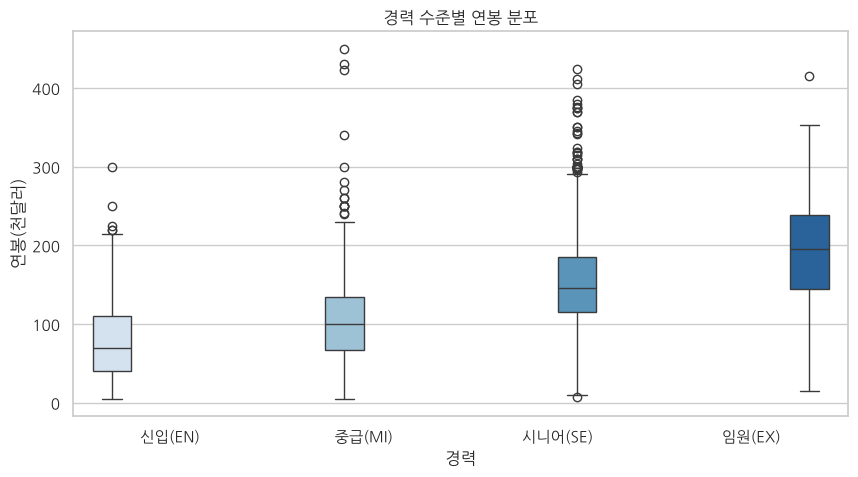

,인원수,중앙값,평균
경력,,,
신입(EN),320,70.0,78.5
중급(MI),805,100.0,104.5
시니어(SE),2516,146.0,153.1
임원(EX),114,196.0,194.9


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='경력', y='연봉(천달러)', hue='경력', palette='Blues', legend=False, ax=ax)
ax.set_title('경력 수준별 연봉 분포')
plt.show()

summary(df, '경력')

In [8]:
# 단계별 상승률 (중앙값 기준)
exp_median = df.groupby('경력', observed=True)['연봉(천달러)'].median()
(exp_median.pct_change() * 100).round(1).rename('이전 단계 대비 상승률(%)')

경력
신입(EN)      NaN
중급(MI)     42.9
시니어(SE)    46.0
임원(EX)     34.2
Name: 이전 단계 대비 상승률(%), dtype: float64

* 한줄 확인 : 신입 70 → 중급 100 → 시니어 146 → 임원 196 (천 달러, 중앙값)
   * 단계마다 **약 34~46%씩** 상승하며, 임원의 중앙값은 신입의 **약 2.8배**

#### 2-2. 기업 규모별 연봉 - 단순 비교의 함정

In [9]:
summary(df, '기업규모')

,인원수,중앙값,평균
기업규모,,,
소기업(S),148,62.1,78.2
중기업(M),3153,140.0,143.1
대기업(L),454,108.5,118.3


* 단순 비교로는 **중기업(M) 140 > 대기업(L) 108.5**로, 중기업이 대기업보다 연봉이 높아 보인다.
 * 정말일까? 기업 규모별로 **미국 회사의 비율**이 다르지 않은지 확인해 보자.

In [10]:
# 기업 규모별 미국 회사 비율(%)
(pd.crosstab(df['기업규모'], df['회사위치'], normalize='index') * 100).round(1)

회사위치,미국,미국 외
기업규모,,
소기업(S),36.5,63.5
중기업(M),86.4,13.6
대기업(L),57.9,42.1


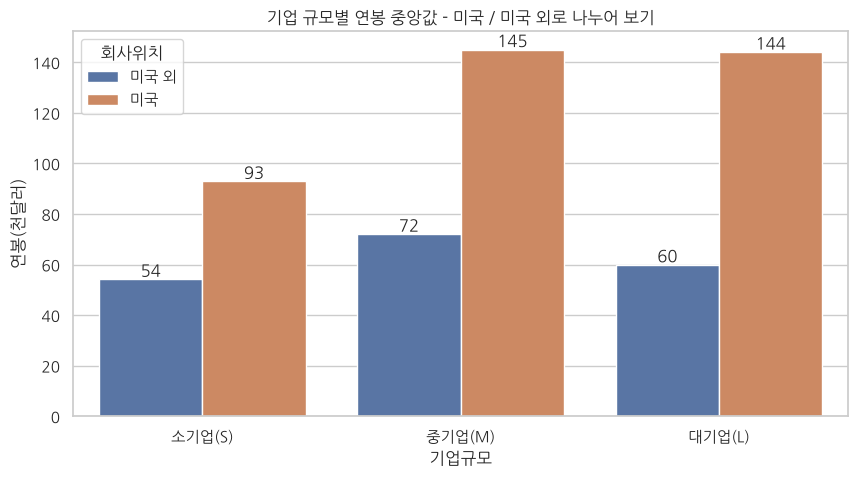

기업규모,소기업(S),중기업(M),대기업(L)
회사위치,,,
미국,92.9,145.0,144.0
미국 외,54.1,72.0,59.9


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x='기업규모', y='연봉(천달러)', hue='회사위치',
            estimator='median', errorbar=None, ax=ax)
ax.set_title('기업 규모별 연봉 중앙값 - 미국 / 미국 외로 나누어 보기')
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f')
plt.show()

summary(df, ['회사위치', '기업규모']).unstack('기업규모')['중앙값']

* 한줄 확인 : 중기업은 **미국 회사 비율이 높아서** 중앙값이 높게 보였던 것
   * 미국 회사만 보면 대기업 144 ≈ 중기업 145로 거의 같다.
   * 소기업은 미국/미국 외 모두 가장 낮다.
 * 이처럼 **제3의 변수(회사 위치)** 가 결과를 왜곡하는 것을 **혼재 변수(confounding)** 라고 한다.

#### 2-3. 원격 근무 비율별 연봉

In [12]:
summary(df, '근무형태')

,인원수,중앙값,평균
근무형태,,,
사무실(0%),1923,139.6,144.3
하이브리드(50%),189,63.3,78.4
완전 원격(100%),1643,135.0,136.5


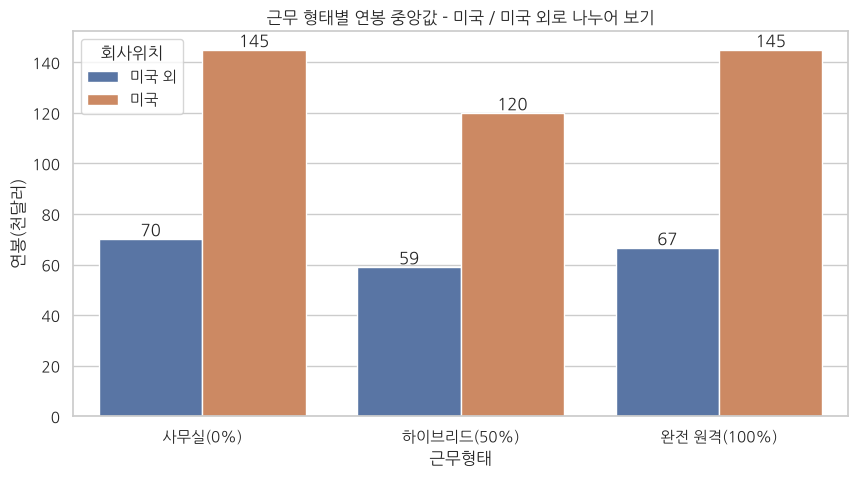

인원수    중앙값     평균
근무형태        회사위치                    
사무실(0%)     미국    1669  145.0  153.2
            미국 외   254   70.2   86.3
하이브리드(50%)  미국      40  120.0  134.0
            미국 외   149   59.1   63.5
완전 원격(100%) 미국    1331  145.0  150.7
            미국 외   312   66.7   75.9

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x='근무형태', y='연봉(천달러)', hue='회사위치',
            estimator='median', errorbar=None, ax=ax)
ax.set_title('근무 형태별 연봉 중앙값 - 미국 / 미국 외로 나누어 보기')
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f')
plt.show()

summary(df, ['근무형태', '회사위치'])

* 한줄 확인 : 하이브리드(50%)의 연봉이 낮게 보이는 이유도 **하이브리드 근무자의 79%(149/189명)가 미국 외 회사**이기 때문
   * 미국 회사 기준으로 사무실 근무와 완전 원격 근무의 중앙값은 **145로 동일**
   * 원격 근무 자체가 연봉을 낮추지는 않는다.

#### 2-4. 경력 × 기업 규모 히트맵

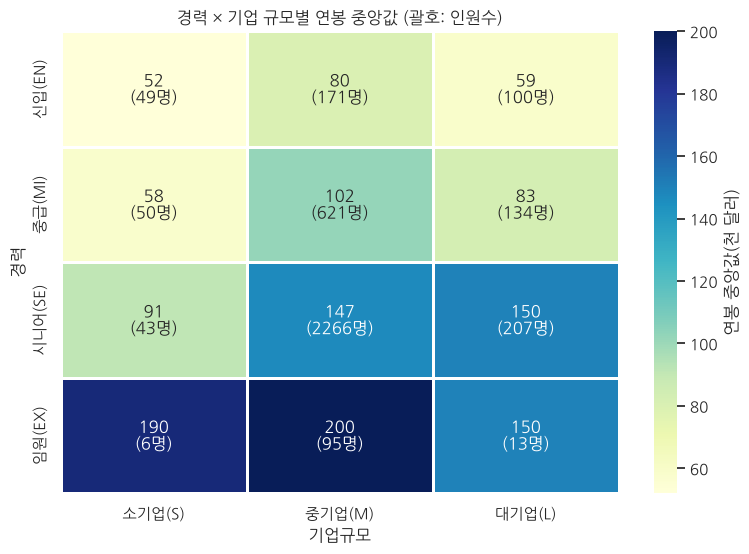

In [14]:
heat_median = df.pivot_table(index='경력', columns='기업규모', values='연봉(천달러)',
                             aggfunc='median', observed=True)
heat_count = df.pivot_table(index='경력', columns='기업규모', values='연봉(천달러)',
                            aggfunc='count', observed=True)

# 칸마다 "중앙값 (인원수)" 형태로 표시
labels = heat_median.round(0).astype(int).astype(str) + '\n(' + heat_count.astype(str) + '명)'

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(heat_median, annot=labels, fmt='', cmap='YlGnBu', linewidths=1,
            cbar_kws={'label': '연봉 중앙값(천 달러)'}, ax=ax)
ax.set_title('경력 × 기업 규모별 연봉 중앙값 (괄호: 인원수)')
plt.show()

* 한줄 확인
   * 신입·중급·시니어 단계에서는 **소기업(S)이 가장 낮다.**
   * 임원(EX)은 대기업 13명, 소기업 6명으로 표본이 적어 순서가 뒤바뀌므로 해석에 주의

#### 2-5. 연도별 추세

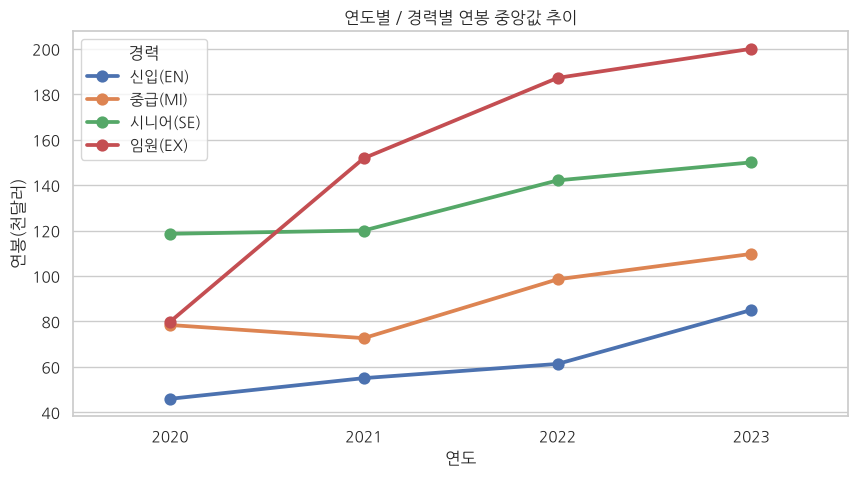

회사위치,미국,미국 외
work_year,,
2020,40.8,59.2
2021,43.5,56.5
2022,80.5,19.5
2023,88.0,12.0


In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.pointplot(data=df, x='work_year', y='연봉(천달러)', hue='경력',
              estimator='median', errorbar=None, ax=ax)
ax.set_title('연도별 / 경력별 연봉 중앙값 추이')
ax.set_xlabel('연도')
plt.show()

pd.crosstab(df['work_year'], df['회사위치'], normalize='index').mul(100).round(1)

* 한줄 확인 : 2020~2021년은 표본이 적고(76명, 230명) 미국 외 비율이 높아, 2022년 이후의 상승을 그대로 **연봉 인상**으로 해석하기는 어렵다.

### 3. 직무 그룹화와 신뢰할 수 있는 순위
 * 93개 직무는 이름만 조금씩 다른 경우가 많다. (예: `ML Engineer` / `Machine Learning Engineer`)
 * 키워드 규칙으로 **6개 직무 그룹**으로 묶어 비교한다. (위에서부터 순서대로 판단)

| 순서 | 직무 그룹 | 키워드 예시 |
|---|---|---|
| 1 | 리더/관리자 | Manager, Head, Director, Lead |
| 2 | ML/AI·리서치 | Machine Learning, ML, AI, Computer Vision, NLP, Deep Learning, Research, Applied Scientist |
| 3 | 데이터 엔지니어링 | Engineer, Architect, ETL, Infrastructure, Developer |
| 4 | 데이터 분석 | Analyst, Analytics, BI, Business Intelligence |
| 5 | 데이터 사이언스 | Scientist, Science, Modeler |
| 6 | 기타 | 위에 해당하지 않는 직무 |

In [16]:
import re

group_rules = [
    ('리더/관리자',      r'Manager|Head|Director|Lead'),
    ('ML/AI·리서치',     r'Machine Learning|\bML\b|\bAI\b|Computer Vision|NLP|Deep Learning|Research|Applied Scientist'),
    ('데이터 엔지니어링', r'Engineer|Architect|ETL|Infrastructure|Developer'),
    ('데이터 분석',      r'Analyst|Analytics|\bBI\b|Business Intelligence'),
    ('데이터 사이언스',   r'Scientist|Science|Modeler'),
]

def job_group(title):
    for name, pattern in group_rules:
        if re.search(pattern, title):
            return name
    return '기타'

df['직무그룹'] = df['job_title'].apply(job_group)

# 그룹별로 어떤 직무가 들어갔는지 확인
for name, titles in df.groupby('직무그룹')['job_title'].unique().items():
    print(f'[{name}] ({len(titles)}개)', ', '.join(sorted(titles)[:8]), '...' if len(titles) > 8 else '')

[ML/AI·리서치] (23개) 3D Computer Vision Researcher, AI Developer, AI Programmer, AI Scientist, Applied Machine Learning Engineer, Applied Machine Learning Scientist, Applied Scientist, Computer Vision Engineer ...
[기타] (4개) Autonomous Vehicle Technician, Data Management Specialist, Data Specialist, Data Strategist 
[데이터 분석] (16개) BI Analyst, BI Data Analyst, Business Data Analyst, Compliance Data Analyst, Data Analyst, Data Analytics Consultant, Data Analytics Specialist, Data Operations Analyst ...
[데이터 사이언스] (7개) Applied Data Scientist, Data Modeler, Data Science Consultant, Data Scientist, Principal Data Scientist, Product Data Scientist, Staff Data Scientist 
[데이터 엔지니어링] (25개) Analytics Engineer, Azure Data Engineer, BI Data Engineer, BI Developer, Big Data Architect, Big Data Engineer, Business Intelligence Engineer, Cloud Data Architect ...
[리더/관리자] (18개) Data Analytics Lead, Data Analytics Manager, Data Lead, Data Manager, Data Science Lead, Data Science Manager, Data Science Tech 

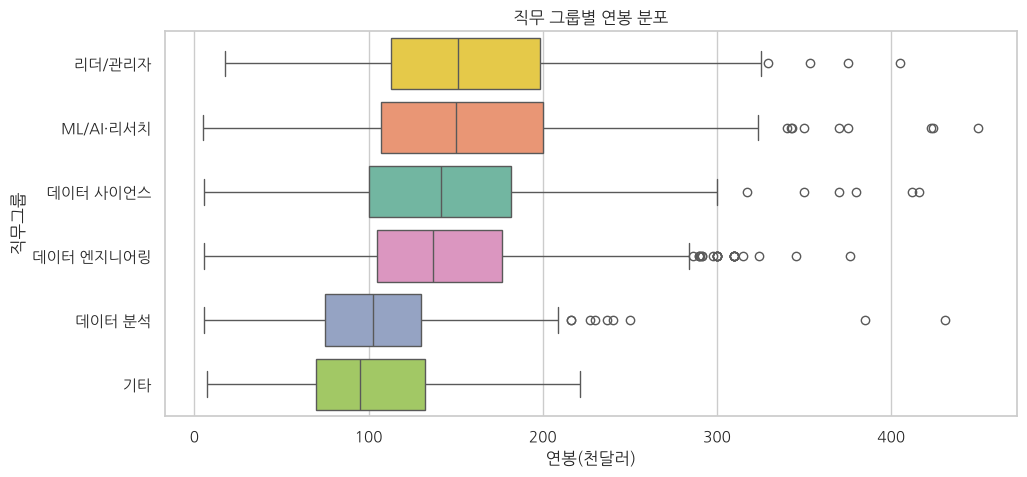

,인원수,중앙값,평균
직무그룹,,,
리더/관리자,182,151.1,158.8
ML/AI·리서치,649,150.0,153.0
데이터 사이언스,886,141.4,139.4
데이터 엔지니어링,1336,137.2,142.9
데이터 분석,683,102.6,105.4
기타,19,95.0,103.0


In [17]:
group_order = (df.groupby('직무그룹')['연봉(천달러)'].median()
                 .sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df, y='직무그룹', x='연봉(천달러)', order=group_order,
            hue='직무그룹', palette='Set2', legend=False, ax=ax)
ax.set_title('직무 그룹별 연봉 분포')
plt.show()

summary(df, '직무그룹').sort_values('중앙값', ascending=False)

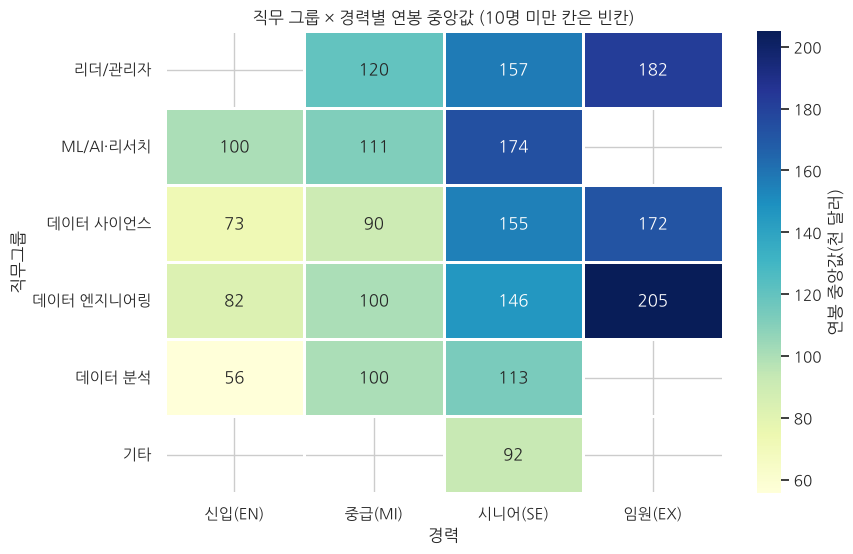

In [18]:
# 직무 그룹 × 경력 : 같은 경력이라면 어떤 직무 그룹이 높을까?
pivot = df.pivot_table(index='직무그룹', columns='경력', values='연봉(천달러)',
                       aggfunc='median', observed=True).loc[group_order]
cnt = df.pivot_table(index='직무그룹', columns='경력', values='연봉(천달러)',
                     aggfunc='count', observed=True).loc[group_order]

# 인원이 10명 미만인 칸은 표시하지 않음
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot.where(cnt >= 10), annot=True, fmt='.0f', cmap='YlGnBu', linewidths=1,
            cbar_kws={'label': '연봉 중앙값(천 달러)'}, ax=ax)
ax.set_title('직무 그룹 × 경력별 연봉 중앙값 (10명 미만 칸은 빈칸)')
plt.show()

* 한줄 확인
   * 전체 중앙값은 **리더/관리자(151) ≈ ML/AI·리서치(150) > 데이터 사이언스(141) > 데이터 엔지니어링(137) > 데이터 분석(103)**
   * 하지만 리더/관리자 그룹은 임원(EX) 비율이 높다. **같은 시니어(SE)끼리 비교하면 ML/AI·리서치(174)가 가장 높다.**
   * 데이터 분석 그룹은 신입(56)과 시니어(113) 단계에서 가장 낮다.

#### 3-1. 직무 순위 - 평균 순위 vs 표본 수를 고려한 중앙값 순위
 * 기본 EDA처럼 **모든 직무의 평균**으로 순위를 매긴 경우와
 * **10명 이상인 직무만** 남기고 **중앙값**으로 순위를 매긴 경우를 비교한다.

In [19]:
MIN_N = 10

job_stat = (df.groupby('job_title')['연봉(천달러)']
              .agg(인원수='count', 중앙값='median', 평균='mean').round(1))

rank_mean = job_stat.sort_values('평균', ascending=False).head(10)
rank_median = job_stat[job_stat['인원수'] >= MIN_N].sort_values('중앙값', ascending=False).head(10)

print('[기본 EDA 방식] 전체 직무 평균 Top 10')
display(rank_mean)
print(f'[추가 분석] {MIN_N}명 이상 직무 중앙값 Top 10')
display(rank_median)

[기본 EDA 방식] 전체 직무 평균 Top 10


,인원수,중앙값,평균
job_title,,,
Data Science Tech Lead,1,375.0,375.0
Cloud Data Architect,1,250.0,250.0
Data Lead,2,212.5,212.5
Data Analytics Lead,2,211.3,211.3
Principal Data Scientist,8,164.6,198.2
Director of Data Science,11,168.0,195.1
Principal Data Engineer,2,192.5,192.5
Machine Learning Software Engineer,10,181.8,192.4
Data Science Manager,58,183.8,191.3


[추가 분석] 10명 이상 직무 중앙값 Top 10


,인원수,중앙값,평균
job_title,,,
Head of Data,10,202.5,183.9
Applied Scientist,58,191.7,190.3
Data Science Manager,58,183.8,191.3
Machine Learning Software Engineer,10,181.8,192.4
Computer Vision Engineer,18,177.3,143.5
Machine Learning Infrastructure Engineer,11,171.6,143.0
Director of Data Science,11,168.0,195.1
Machine Learning Scientist,26,167.9,163.2
ML Engineer,34,160.0,158.4


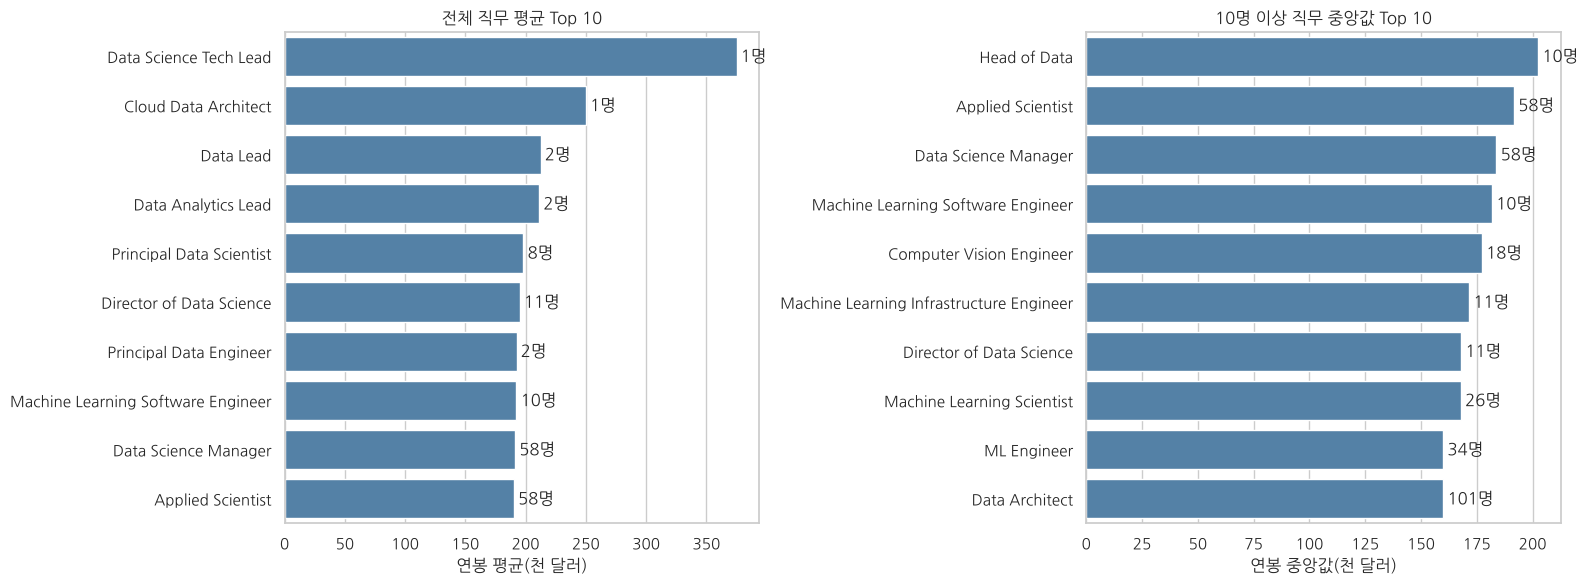

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, col, title in [
    (axes[0], rank_mean, '평균', '전체 직무 평균 Top 10'),
    (axes[1], rank_median, '중앙값', f'{MIN_N}명 이상 직무 중앙값 Top 10'),
]:
    sns.barplot(x=data[col], y=data.index, color='steelblue', ax=ax)
    ax.bar_label(ax.containers[0], labels=[f'{n}명' for n in data['인원수']], padding=3)
    ax.set_title(title)
    ax.set_xlabel(f'연봉 {col}(천 달러)')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

* 한줄 확인
   * 평균 Top 10에는 **1~2명짜리 직무가 다수** 포함 (`Data Science Tech Lead` 1명, `Cloud Data Architect` 1명 등)
   * 10명 이상 기준으로 보면 `Head of Data`, `Applied Scientist`(58명), `Data Science Manager`(58명) 순
   * **인원이 많은 Applied Scientist, Data Science Manager가 실제로 높은 연봉 직무**라고 말할 수 있다.

#### 3-2. 국가 순위 - 평균 순위 vs 표본 수를 고려한 중앙값 순위
 * 회사 위치(`company_location`) 기준

In [21]:
country_kor = {
    'US': '미국', 'CA': '캐나다', 'GB': '영국', 'DE': '독일', 'ES': '스페인', 'IN': '인도',
    'FR': '프랑스', 'AU': '호주', 'NL': '네덜란드', 'PT': '포르투갈', 'GR': '그리스', 'BR': '브라질',
    'MX': '멕시코', 'IL': '이스라엘', 'PR': '푸에르토리코', 'RU': '러시아', 'NZ': '뉴질랜드',
    'BA': '보스니아 헤르체고비나', 'IE': '아일랜드', 'JP': '일본', 'SE': '스웨덴',
}

country_stat = (df.groupby('company_location')['연봉(천달러)']
                  .agg(인원수='count', 중앙값='median', 평균='mean').round(1))
country_stat.insert(0, '국가', country_stat.index.map(lambda c: country_kor.get(c, c)))

print('[기본 EDA 방식] 전체 국가 평균 Top 10')
display(country_stat.sort_values('평균', ascending=False).head(10))

country_rank = country_stat[country_stat['인원수'] >= MIN_N].sort_values('중앙값', ascending=False)
print(f'[추가 분석] {MIN_N}명 이상 국가 중앙값 순위 ({len(country_rank)}개국)')
display(country_rank)

[기본 EDA 방식] 전체 국가 평균 Top 10


,국가,인원수,중앙값,평균
company_location,,,,
IL,이스라엘,2,271.4,271.4
PR,푸에르토리코,4,167.5,167.5
US,미국,3040,145.0,151.8
RU,러시아,3,106.0,140.3
CA,캐나다,87,120.0,131.9
NZ,뉴질랜드,1,125.0,125.0
BA,보스니아 헤르체고비나,1,120.0,120.0
IE,아일랜드,7,101.9,114.9
JP,일본,6,75.7,114.1


[추가 분석] 10명 이상 국가 중앙값 순위 (13개국)


,국가,인원수,중앙값,평균
company_location,,,,
US,미국,3040,145.0,151.8
CA,캐나다,87,120.0,131.9
GB,영국,172,79.5,86.9
NL,네덜란드,13,73.5,78.7
DE,독일,56,72.7,88.3
AU,호주,14,72.5,80.0
MX,멕시코,10,66.0,97.2
FR,프랑스,34,59.0,66.1
PT,포르투갈,14,52.9,50.5


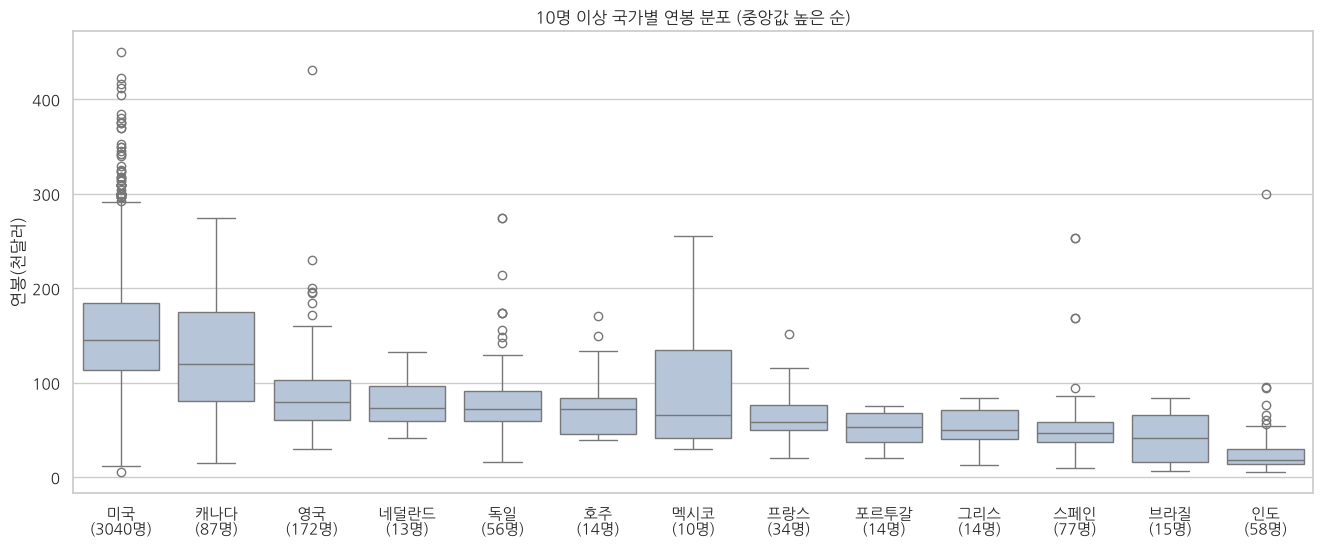

In [22]:
# 10명 이상 국가의 연봉 분포 - 라벨을 데이터에서 직접 만들어 순서가 어긋나지 않도록 함
order = country_rank.index
data = df[df['company_location'].isin(order)].copy()
data['국가'] = data['company_location'].map(lambda c: f'{country_kor.get(c, c)}\n({country_stat.loc[c, "인원수"]}명)')
label_order = [f'{country_kor.get(c, c)}\n({country_stat.loc[c, "인원수"]}명)' for c in order]

fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(data=data, x='국가', y='연봉(천달러)', order=label_order, color='lightsteelblue', ax=ax)
ax.set_title(f'{MIN_N}명 이상 국가별 연봉 분포 (중앙값 높은 순)')
ax.set_xlabel('')
plt.show()

* 한줄 확인
   * 기본 EDA의 1위 이스라엘(IL)은 **2명**, 2위 푸에르토리코(PR)는 **4명**의 데이터
   * 10명 이상 국가 기준으로는 **미국 > 캐나다 > 영국** 순이며, 미국과 캐나다가 다른 나라보다 확실히 높다.
   * 국가별 박스플롯의 라벨을 데이터에서 직접 만들어, 라벨과 막대 순서가 어긋나지 않게 했다.

#### 3-3. 같은 직무, 다른 나라 - 데이터가 충분한 주요 직무 비교
 * 인원이 많은 4개 직무를 미국 / 미국 외로 나누어 비교

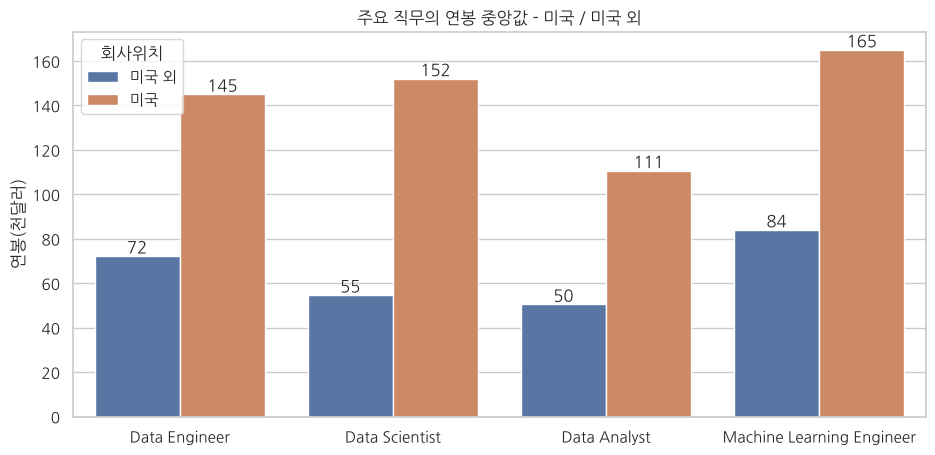

인원수         중앙값           평균      
회사위치                        미국 미국 외     미국  미국 외     미국  미국 외
job_title                                                    
Data Analyst               525   87  110.6  50.4  116.7  60.8
Data Engineer              907  133  145.0  72.2  152.8  74.5
Data Scientist             674  166  152.0  54.7  158.3  70.2
Machine Learning Engineer  219   70  165.0  84.0  174.4  93.1

In [23]:
top_jobs = ['Data Engineer', 'Data Scientist', 'Data Analyst', 'Machine Learning Engineer']

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=df[df['job_title'].isin(top_jobs)], x='job_title', y='연봉(천달러)',
            hue='회사위치', order=top_jobs, estimator='median', errorbar=None, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f')
ax.set_title('주요 직무의 연봉 중앙값 - 미국 / 미국 외')
ax.set_xlabel('')
plt.show()

summary(df[df['job_title'].isin(top_jobs)], ['job_title', '회사위치']).unstack('회사위치')

* 한줄 확인 : 같은 직무라도 **미국 회사의 연봉 중앙값이 약 2~2.8배** 높다. 회사 위치가 연봉에 가장 큰 영향을 주는 변수 중 하나

### 4. 정리
| 질문 | 단순 비교 결과 | 추가 분석 결과 |
|---|---|---|
| 경력에 따라 연봉이 얼마나 오를까? | - | 신입 70 → 중급 100 → 시니어 146 → 임원 196 (천 달러), 단계마다 약 34~46% 상승 |
| 대기업이 연봉이 높을까? | 중기업 > 대기업 | 미국 회사만 보면 **대기업 ≈ 중기업**, 소기업이 가장 낮음 |
| 원격 근무는 연봉이 낮을까? | 하이브리드가 가장 낮음 | 하이브리드의 79%가 미국 외 회사. 미국 기준 **사무실 = 완전 원격** |
| 연봉이 가장 높은 직무는? | Data Science Tech Lead (1명) | 10명 이상 기준 Head of Data, **Applied Scientist, Data Science Manager** |
| 연봉이 가장 높은 국가는? | 이스라엘 (2명) | 10명 이상 기준 **미국 > 캐나다 > 영국** |
| 직무 그룹별로는? | 리더/관리자 ≈ ML/AI·리서치가 가장 높음 | 같은 시니어끼리는 **ML/AI·리서치가 가장 높고**, 데이터 분석은 신입·시니어에서 가장 낮음 |

#### 배운 점
 * 평균 대신 **중앙값**, 그리고 항상 **표본 수**를 함께 확인하기
 * 그룹을 비교할 때는 결과를 왜곡하는 **혼재 변수**(여기서는 회사 위치)가 없는지 나누어 보기
 * 비슷한 범주(직무명)는 **그룹화**하면 더 신뢰할 수 있는 결론을 얻을 수 있다.

#### 추가로 해 볼 만한 분석
 * 경력, 직무 그룹, 회사 위치, 기업 규모, 근무 형태로 **연봉 예측 모델**(선형 회귀, RandomForest)을 만들고 변수 중요도 확인